# Content Monetization Modeler
## YouTube advertising revenue with Python, regression and Streamlit

**Learning objective:** explain the whole process from a CSV to a saved prediction model.
The target is `ad_revenue_usd` for one reporting observation. The source is synthetic.
This notebook runs the complete workflow, including five-model training. It regenerates
the model, cleaned data, metrics and figures in the project folder.

Read the sections in order. The dashboard uses the same functions as this notebook.

## 1. Imports and project folder
`Path` handles file locations. `sys.path` lets this notebook import the small Python
files in the project. Run from the project folder or its `notebooks` folder.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Image

project_root = Path.cwd()
if not (project_root / "utils.py").exists():
    project_root = project_root.parent
if not (project_root / "utils.py").exists():
    raise FileNotFoundError("Open this notebook inside the supplied project folder.")
sys.path.insert(0, str(project_root))

from utils import (INPUTS, NUMERIC, TARGET, load_data, split_data, add_features,
                   predict_revenue, read_json)
from train_model import run_training
print("Project folder:", project_root.name)

Project folder: content-monetization-modeler


## 2. Load and validate the data
`load_data` checks the schema, numbers and dates, then removes exact duplicates.
It keeps distinct records that happen to share a video ID. The original CSV is preserved.

In [2]:
data, quality = load_data()
display(pd.Series(quality).to_frame("Result"))
display(data.head())
display(data.dtypes.to_frame("Data type"))

,Result
raw_rows,122400
duplicates_removed,2400
clean_rows,120000
missing_after_dedup,"{'video_id': 0, 'date': 0, 'views': 0, 'likes'..."
unique_video_ids,5000
repeated_video_date_rows,3849


,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388


,Data type
video_id,object
date,datetime64[ns]
views,int64
likes,float64
comments,float64
watch_time_minutes,float64
video_length_minutes,float64
subscribers,int64
category,object
device,object


## 3. Missing values and synthetic-data issues
After deduplication, likes, comments and watch time each have 6,000 missing values.
A missing value means unknown, not zero. Video IDs are not stable real-world identities
in this synthetic source: the same ID can have several categories and video lengths.

In [3]:
missing = data.isna().sum().to_frame("Missing rows")
missing["Percent"] = missing["Missing rows"] / len(data) * 100
display(missing)
print("Repeated video/date pairs beyond the first:",
      data.duplicated(["video_id", "date"]).sum())
print("IDs with multiple categories:",
      (data.groupby("video_id")["category"].nunique() > 1).sum())
print("Average watch time greater than video length:",
      ((data["watch_time_minutes"] / data["views"]) > data["video_length_minutes"]).sum())

,Missing rows,Percent
video_id,0,0.0
date,0,0.0
views,0,0.0
likes,6000,5.0
comments,6000,5.0
watch_time_minutes,6000,5.0
video_length_minutes,0,0.0
subscribers,0,0.0
category,0,0.0
device,0,0.0


Repeated video/date pairs beyond the first: 3849
IDs with multiple categories: 5000
Average watch time greater than video length: 7280


## 4. Separate training, validation and test data
Training fits the models. Validation compares them. The final test set checks the
selected model. We split by video ID, using a fixed random seed, so the same ID cannot
appear on both sides of an evaluation. The 60/20/20 percentages refer to IDs, not rows.
Because the IDs themselves are synthetic, this is a conservative safeguard rather than
evidence of real-world channel generalization. Dates are used for description, not forecasting.

In [4]:
train, validation, test = split_data(data)
parts = {"train": train, "validation": validation, "test": test}
display(pd.DataFrame({name: {"rows": len(frame), "video_ids": frame.video_id.nunique()}
                      for name, frame in parts.items()}).T)
assert set(train.video_id).isdisjoint(validation.video_id)
assert set(train.video_id).isdisjoint(test.video_id)
assert set(validation.video_id).isdisjoint(test.video_id)
print("No video IDs overlap between partitions.")

,rows,video_ids
train,72176,3000
validation,23967,1000
test,23857,1000


No video IDs overlap between partitions.


## 5. Numerical exploration on the training partition
Look at the center, spread and ranges before choosing preparation steps. All views
are close to 10,000. A model trained on this source has no demonstrated reliability
for a million-view video. We retain reasonable positive values even if an IQR rule flags them.

In [5]:
display(train[NUMERIC + [TARGET]].describe().round(2))
outliers = {}
for column in NUMERIC + [TARGET]:
    q1, q3 = train[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers[column] = ((train[column] < q1 - 1.5 * iqr) |
                        (train[column] > q3 + 1.5 * iqr)).sum()
display(pd.Series(outliers, name="IQR flags (not automatic deletions)"))

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,ad_revenue_usd
count,72176.00,68580.00,68609.00,68565.00,72176.00,72176.00,72176.00
mean,9999.90,1098.60,274.14,37504.49,16.02,501598.55,252.50
std,100.29,519.74,129.49,12986.57,8.09,288403.20,61.94
min,9521.00,195.00,48.00,14659.11,2.00,1018.00,127.26
25%,9932.00,649.00,162.00,26308.89,9.03,251742.75,199.75
50%,10000.00,1101.00,273.00,37466.35,15.98,503686.50,252.40
75%,10067.00,1544.00,386.00,48727.83,23.03,751473.25,305.36
max,10468.00,2048.00,515.00,61557.67,30.00,999997.00,381.11


views                   520
likes                     0
comments                  0
watch_time_minutes        0
video_length_minutes      0
subscribers               0
ad_revenue_usd            0
Name: IQR flags (not automatic deletions), dtype: int64

## 6. Relationships, groups and reporting dates
Watch time has a strong observed relationship with revenue. Group averages across
categories, devices and countries differ only slightly in this source. Correlation is
not proof that changing an input causes revenue to change. A regression-line slope is
also not a unit-independent measure of correlation strength.

In [6]:
display(train[NUMERIC + [TARGET]].corr().round(4))
for column in ["category", "country", "device"]:
    display(train.groupby(column)[TARGET].agg(["count", "mean", "median"]).round(2))
monthly = train.set_index("date")[TARGET].resample("MS").agg(["count", "mean"])
display(monthly.round(2))

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,ad_revenue_usd
views,1.0000,0.0164,0.0153,0.0215,0.0037,-0.0034,0.0326
likes,0.0164,1.0000,-0.0008,0.0019,-0.0016,0.0024,0.1453
comments,0.0153,-0.0008,1.0000,-0.0053,0.0000,0.0050,0.0303
watch_time_minutes,0.0215,0.0019,-0.0053,1.0000,-0.0020,0.0035,0.9888
video_length_minutes,0.0037,-0.0016,0.0000,-0.0020,1.0000,0.0066,-0.0016
subscribers,-0.0034,0.0024,0.0050,0.0035,0.0066,1.0000,0.0036
ad_revenue_usd,0.0326,0.1453,0.0303,0.9888,-0.0016,0.0036,1.0000


,count,mean,median
category,,,
Education,12065,252.59,252.20
Entertainment,12075,252.65,252.39
Gaming,11992,253.11,253.46
Lifestyle,11960,251.58,251.27
Music,12099,252.08,252.14
Tech,11985,252.99,253.02


,count,mean,median
country,,,
AU,11977,252.09,252.48
CA,12098,252.93,253.12
DE,12189,252.40,252.67
IN,12138,252.16,251.91
UK,11949,252.79,251.26
US,11825,252.63,252.84


,count,mean,median
device,,,
Desktop,18081,252.14,252.59
Mobile,18003,253.15,253.90
TV,18089,252.19,251.38
Tablet,18003,252.53,252.02


,count,mean
date,,
2024-06-01,4317,252.42
2024-07-01,6087,251.80
2024-08-01,6203,252.15
2024-09-01,5860,253.57
2024-10-01,6226,252.08
2024-11-01,5904,252.52
2024-12-01,6007,253.44
2025-01-01,6241,252.03
2025-02-01,5511,251.94


## 7. Two understandable engineered features
**Engagement rate** = (likes + comments) / views.
**Average watch minutes** = total watch minutes / views.
We calculate these before imputation. If an input is missing, the ratio remains missing
and gets its own fitted median later. Therefore an imputed ratio need not equal the
ratio of separately imputed raw inputs. Missing indicators preserve which fields were unknown.
The target, video ID and date never enter the model as predictors.

In [7]:
display(add_features(train).head())
example = train[INPUTS].head(1).copy()
example["views"] = 10000
example["likes"] = 1000
example["comments"] = 200
example["watch_time_minutes"] = 30000
display(add_features(example)[["engagement_rate", "average_watch_minutes"]])

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,engagement_rate,average_watch_minutes
0,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,0.155093,2.666789
1,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,0.098632,1.518393
2,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,0.214519,5.678187
3,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,0.142814,3.122834
5,10002,843.0,159.0,35131.756228,12.491826,541268,Music,TV,CA,0.100180,3.512473


,engagement_rate,average_watch_minutes
0,0.12,3.0


## 8. Preprocessing and five regression models
`build_pipeline` connects feature creation, median imputation, missing indicators,
numeric scaling, categorical imputation, one-hot encoding and the estimator.
Only training rows fit these steps during comparison. Scaling also runs for the tree
models to keep one beginner-friendly preprocessing path; trees do not require it.

We compare Linear Regression, Ridge, Decision Tree, Random Forest and Gradient Boosting.
Settings are fixed and modest; this project does not claim exhaustive hyperparameter tuning.
The selection rule is set in advance: lowest validation RMSE, with preference for a
simpler model when its RMSE is within $0.05 of the lowest value.

The next cell runs all five models. It usually takes under two minutes on the tested machine.
The selected model is then fitted afresh on training + validation, and evaluated on test.

In [8]:
comparison, test_scores = run_training()
display(comparison.round(4))
display(pd.Series({key: test_scores[key] for key in ["model", "mae", "rmse", "r2", "test_rows"]}))

Training Linear Regression ...


Training Ridge Regression ...


Training Decision Tree ...


Training Random Forest ...


Training Gradient Boosting ...


Selected Linear Regression. Test MAE=$3.17, RMSE=$13.61, R2=0.9516


,model,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,fit_and_score_seconds,selected
0,Linear Regression,3.2549,13.8829,0.9498,3.2371,13.8101,0.9506,0.26,True
1,Ridge Regression,3.3074,13.8837,0.9497,3.2890,13.8082,0.9506,0.25,False
2,Decision Tree,5.1865,14.0627,0.9484,5.2908,14.1681,0.9480,0.63,False
3,Random Forest,3.3152,12.8450,0.9570,3.6774,13.8766,0.9501,16.90,False
4,Gradient Boosting,4.1043,13.9299,0.9494,4.1122,13.9009,0.9499,12.00,False


model        Linear Regression
mae                   3.174051
rmse                 13.611592
r2                    0.951562
test_rows                23857
dtype: object

## 9. Read the errors correctly
MAE is an average dollar error. RMSE penalizes large mistakes more. R² compares the
model with predicting a mean and is not a percentage accuracy. The mean-only reference
is a simple check on usefulness, not one of the five candidate algorithms.
Watch-time availability strongly affects error, so inspect the two groups separately.

In [9]:
display(pd.DataFrame(test_scores["watch_time_groups"]).T.round(4))
display(pd.Series(test_scores["mean_baseline"], name="Mean-only test reference"))
print("Large errors concentrate among observations with missing watch time.")

,rows,mae,rmse,r2
observed,22660.0,0.6121,2.0283,0.9989
missing,1197.0,51.6736,60.1231,0.0174


mae     53.269800
rmse    61.846423
r2      -0.000001
Name: Mean-only test reference, dtype: float64

Large errors concentrate among observations with missing watch time.


## 10. Visual analysis and model diagnostics
The distribution, outlier, relationship, group, correlation and monthly charts use
training rows. The missing-value chart audits all deduplicated rows. Validation scores
compare models. Error plots use the final test set. These populations are labeled.

Read charts 01–10 in order. Compare groups on axes starting at zero so small differences
do not appear exaggerated. The residual plot reveals errors hidden by a single average.

01_missing_values


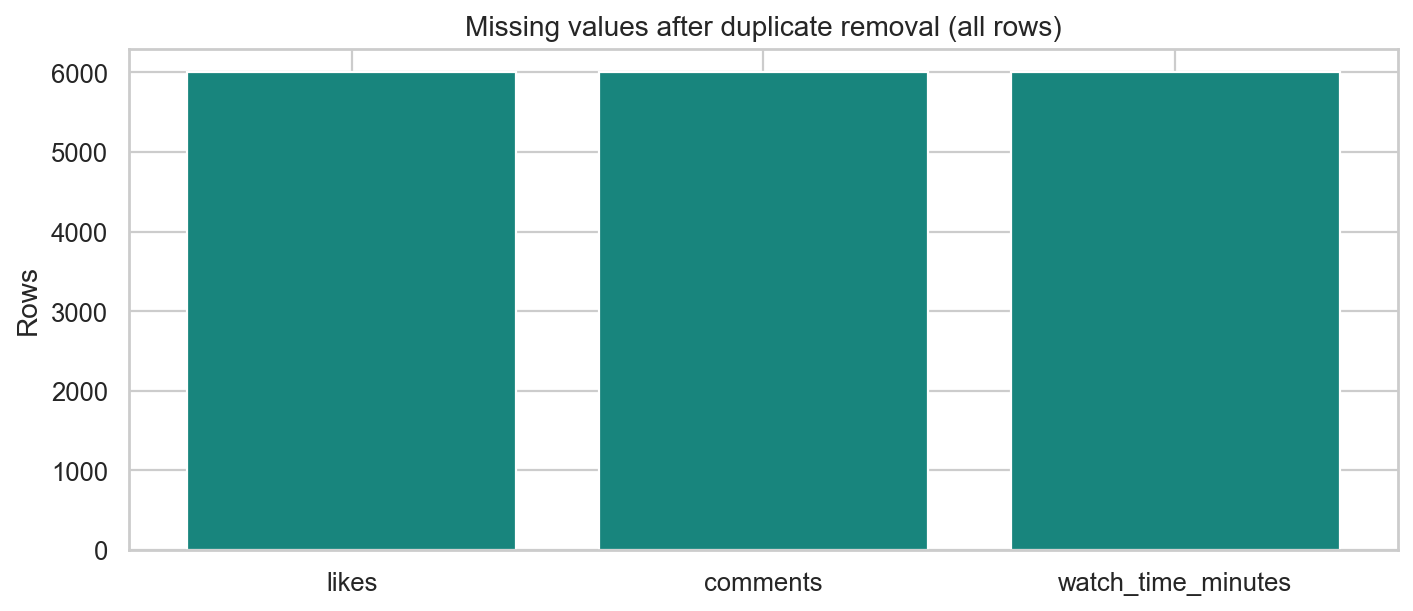

02_distributions


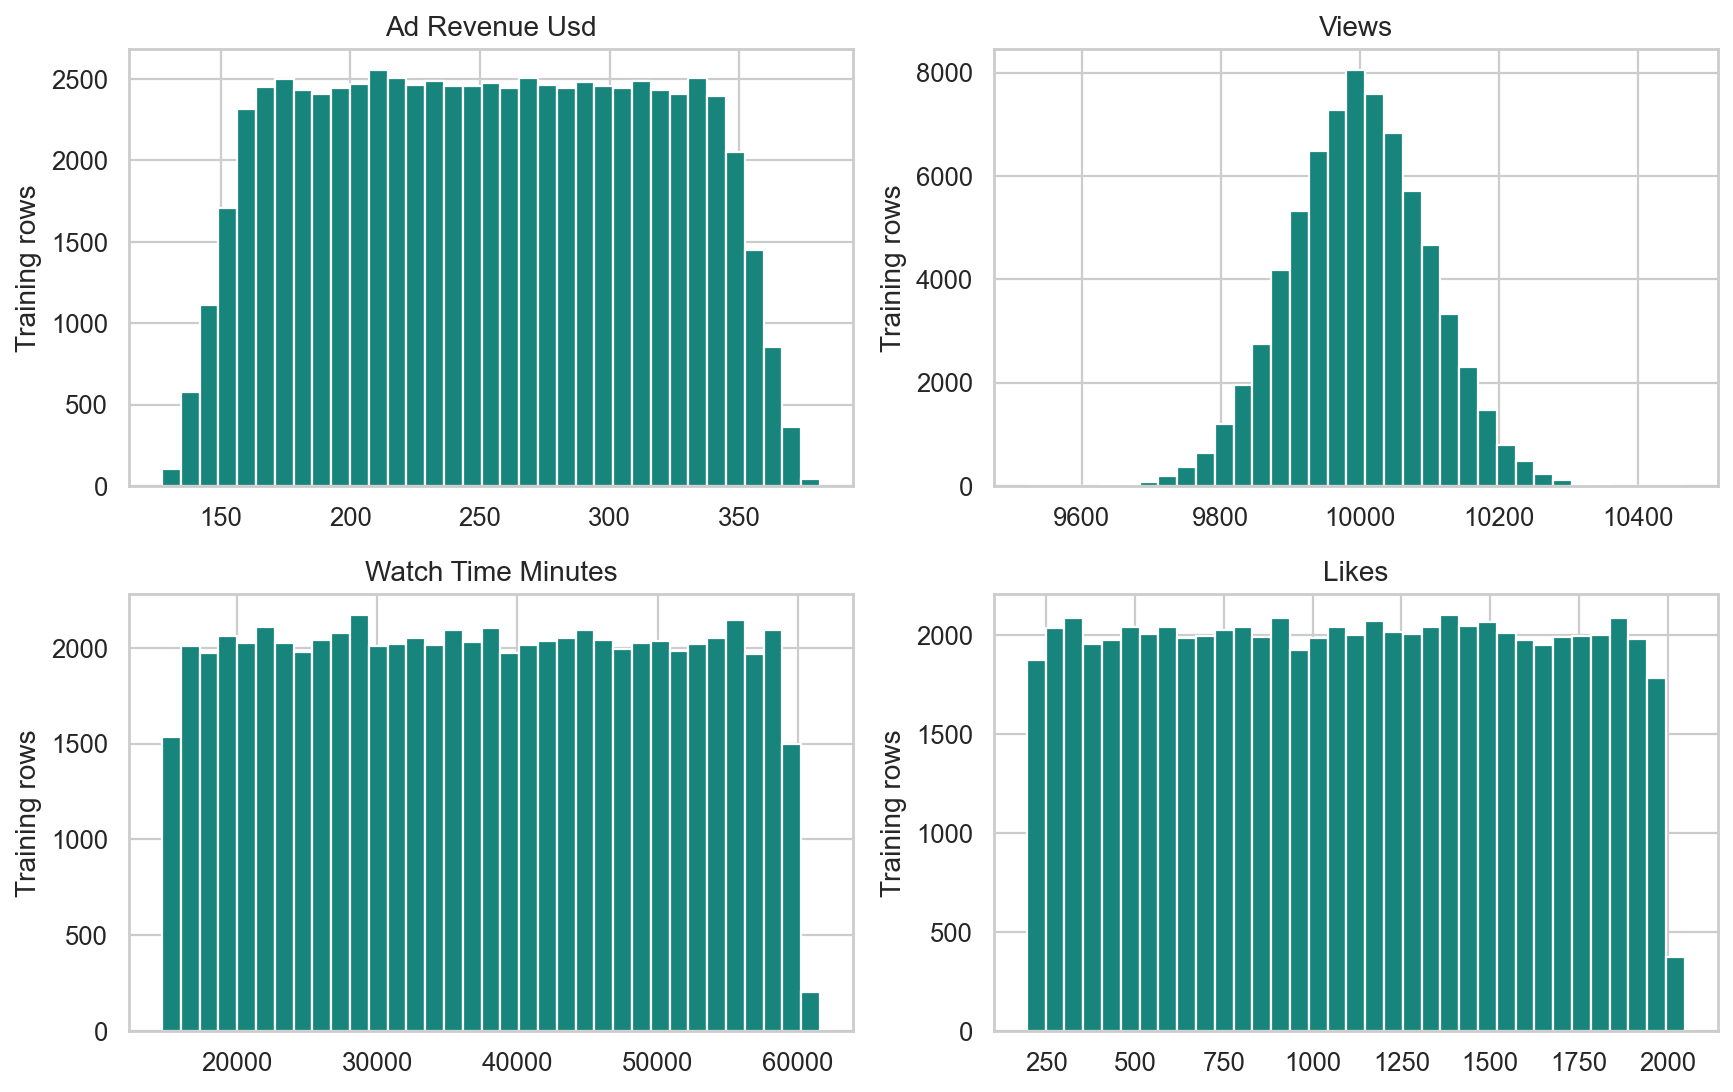

03_outliers


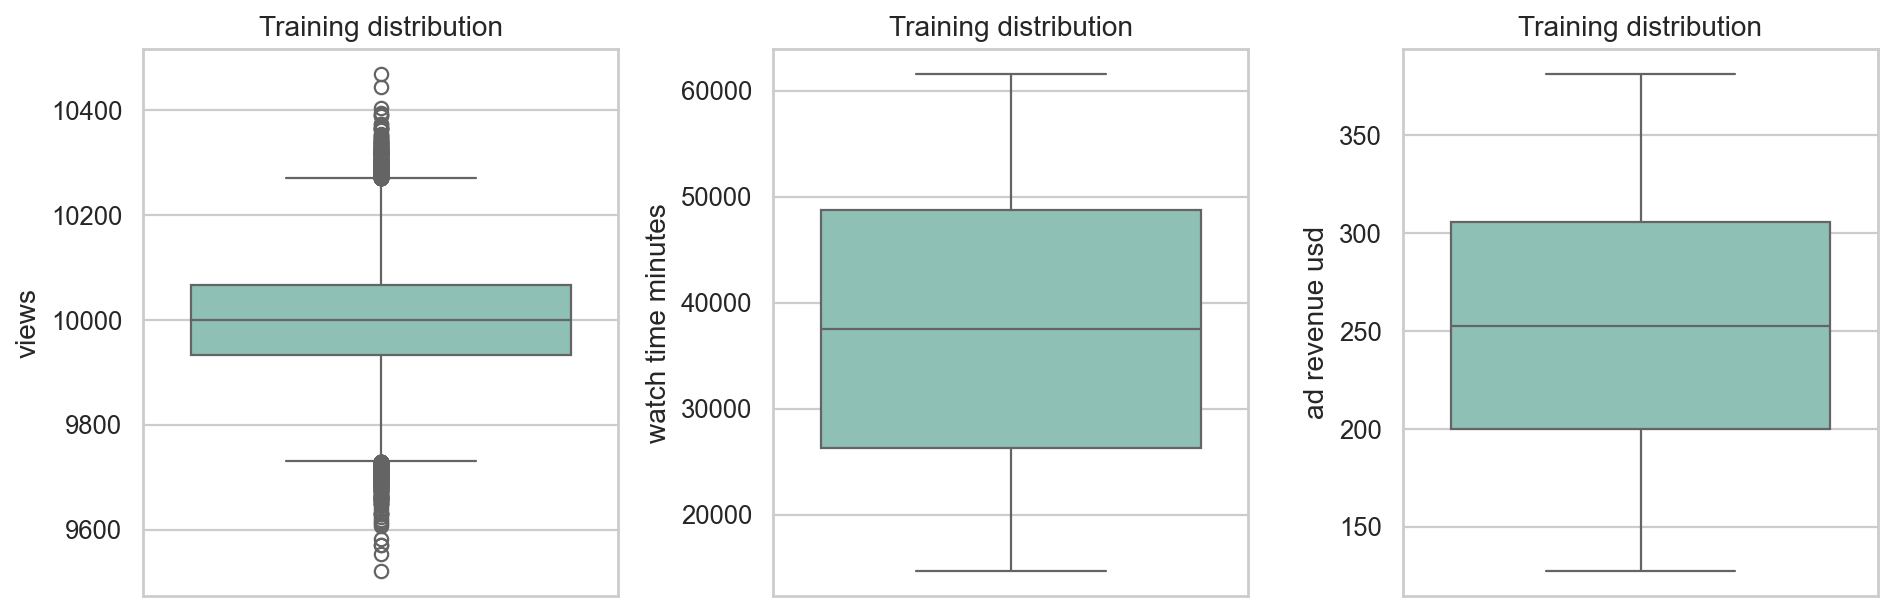

04_revenue_relationships


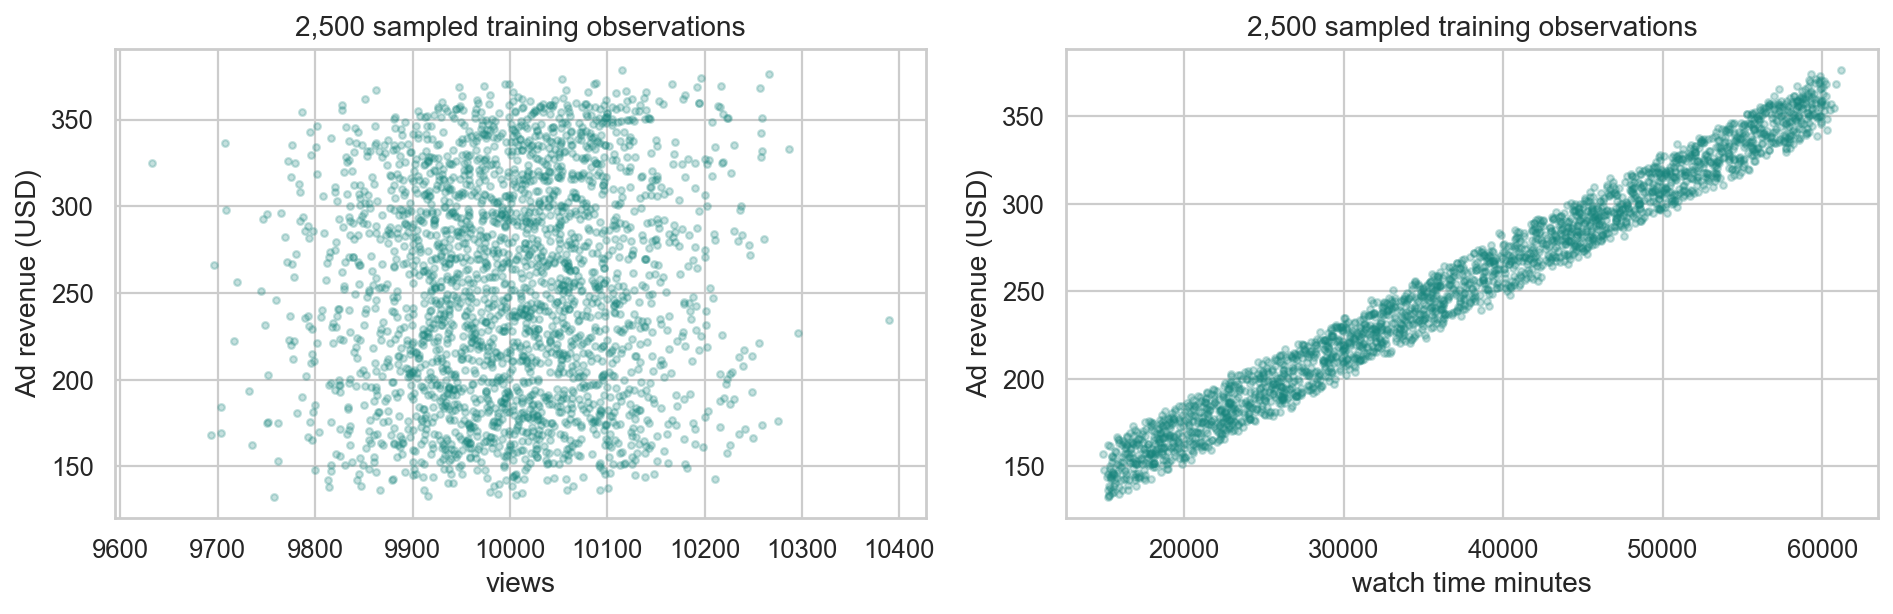

05_group_comparisons


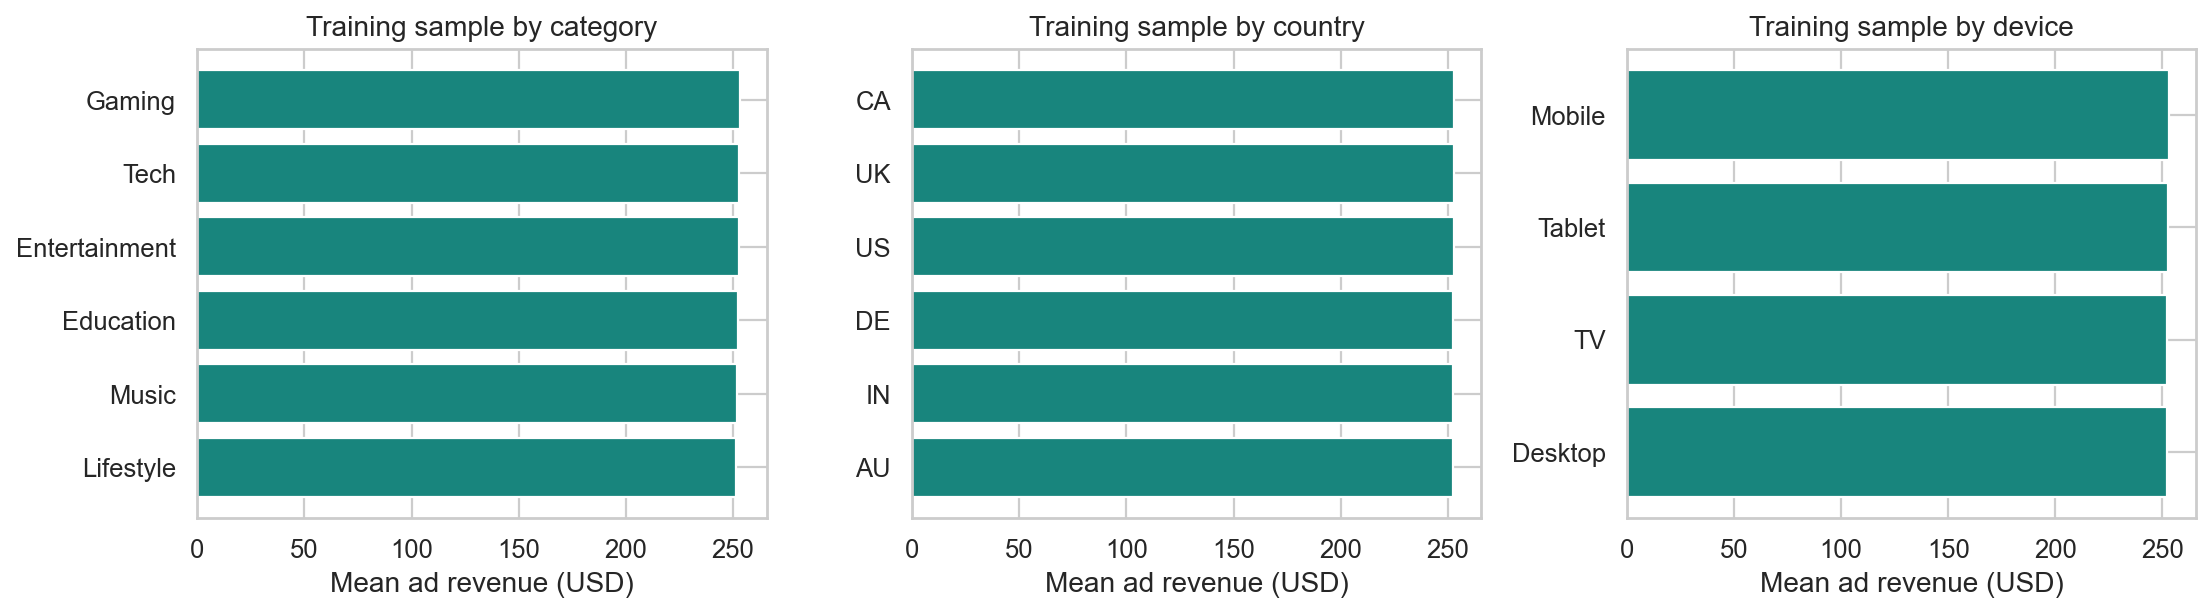

06_correlations


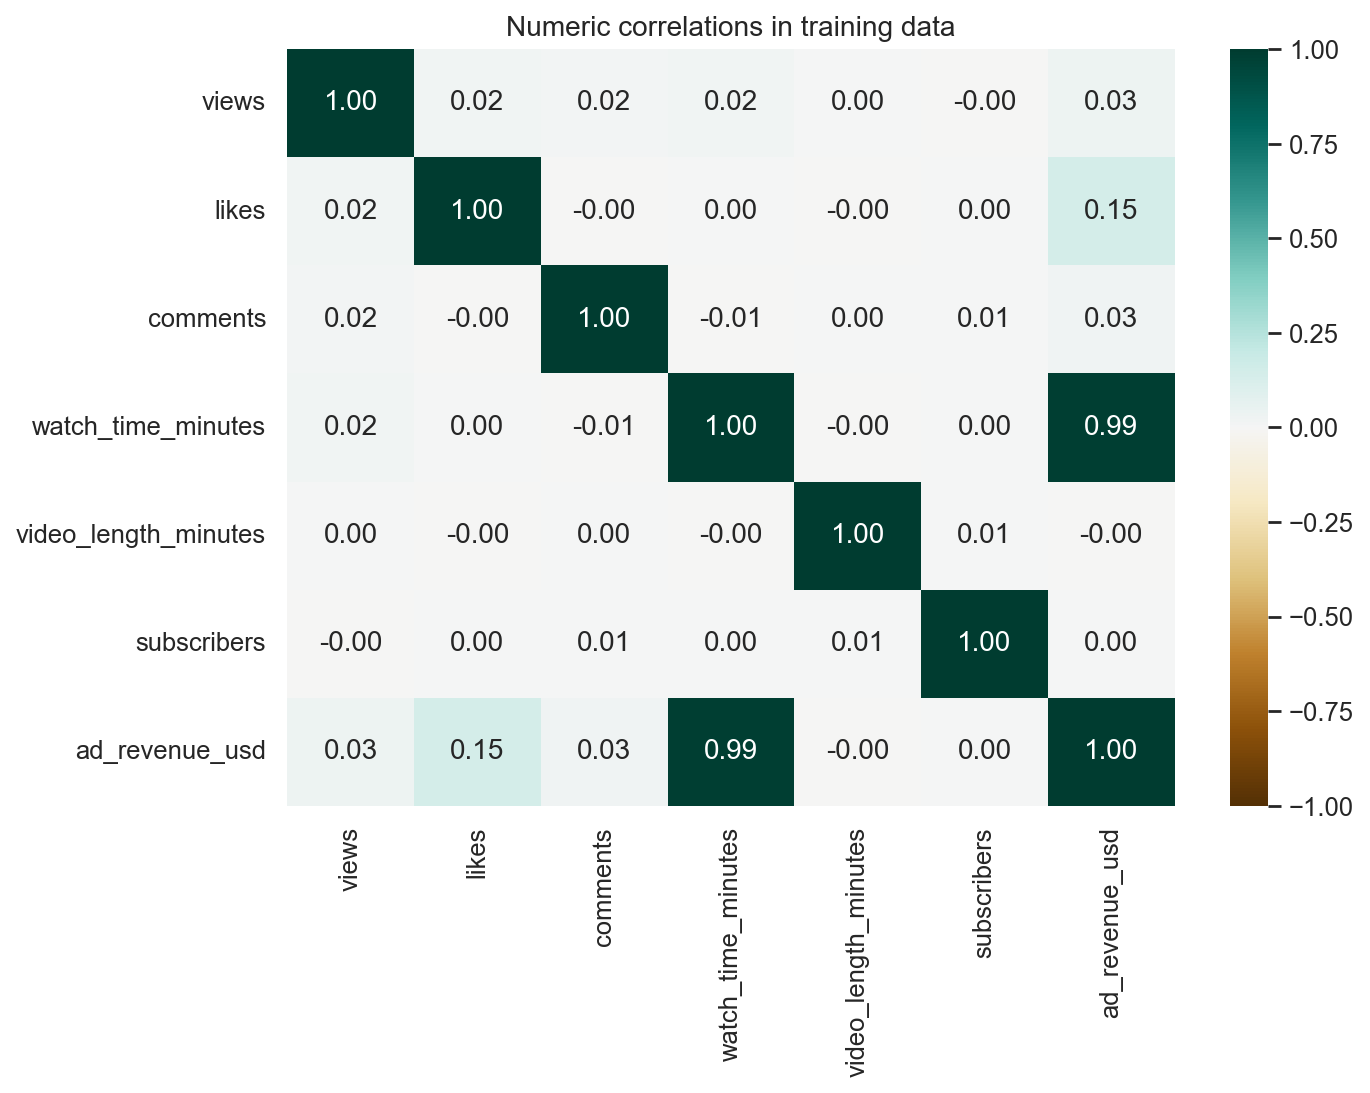

07_monthly_sample


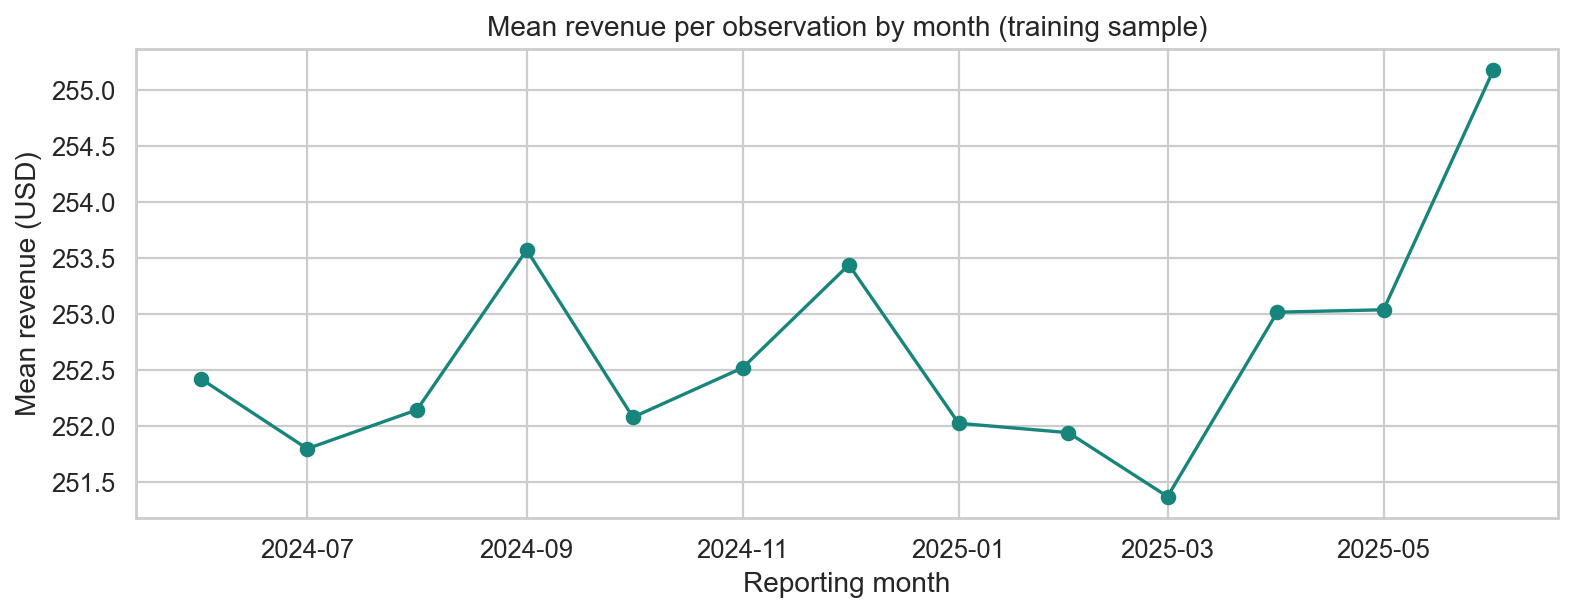

08_model_comparison


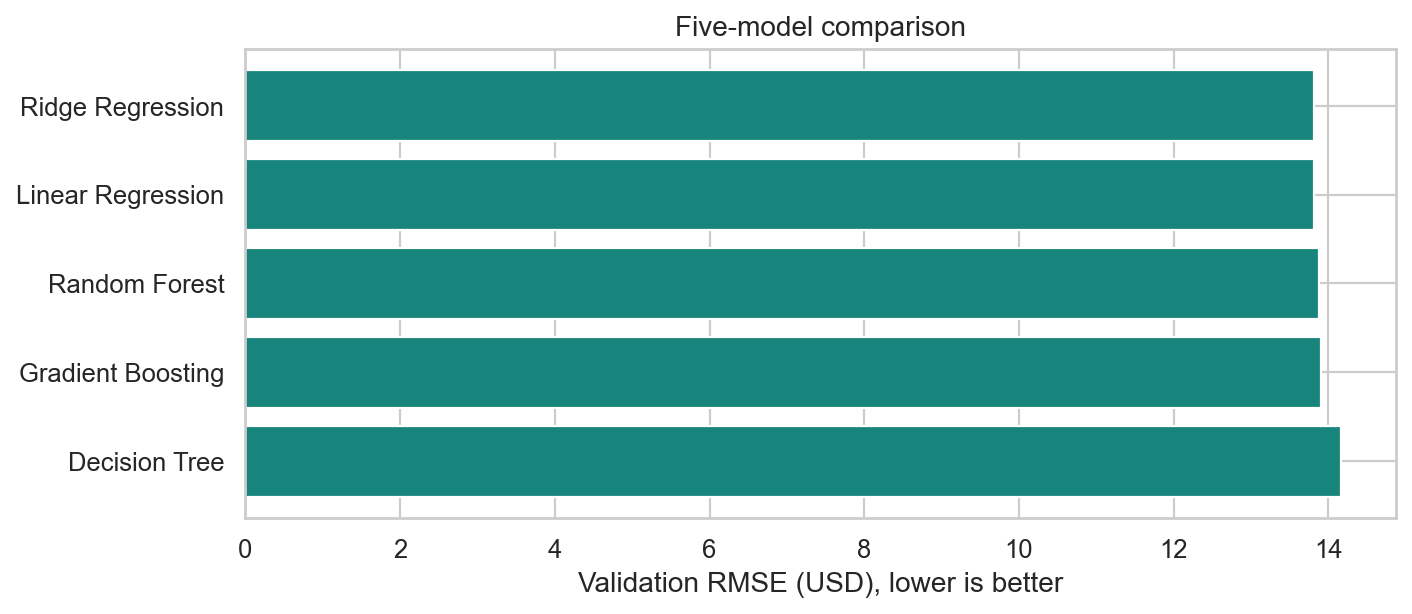

09_prediction_errors


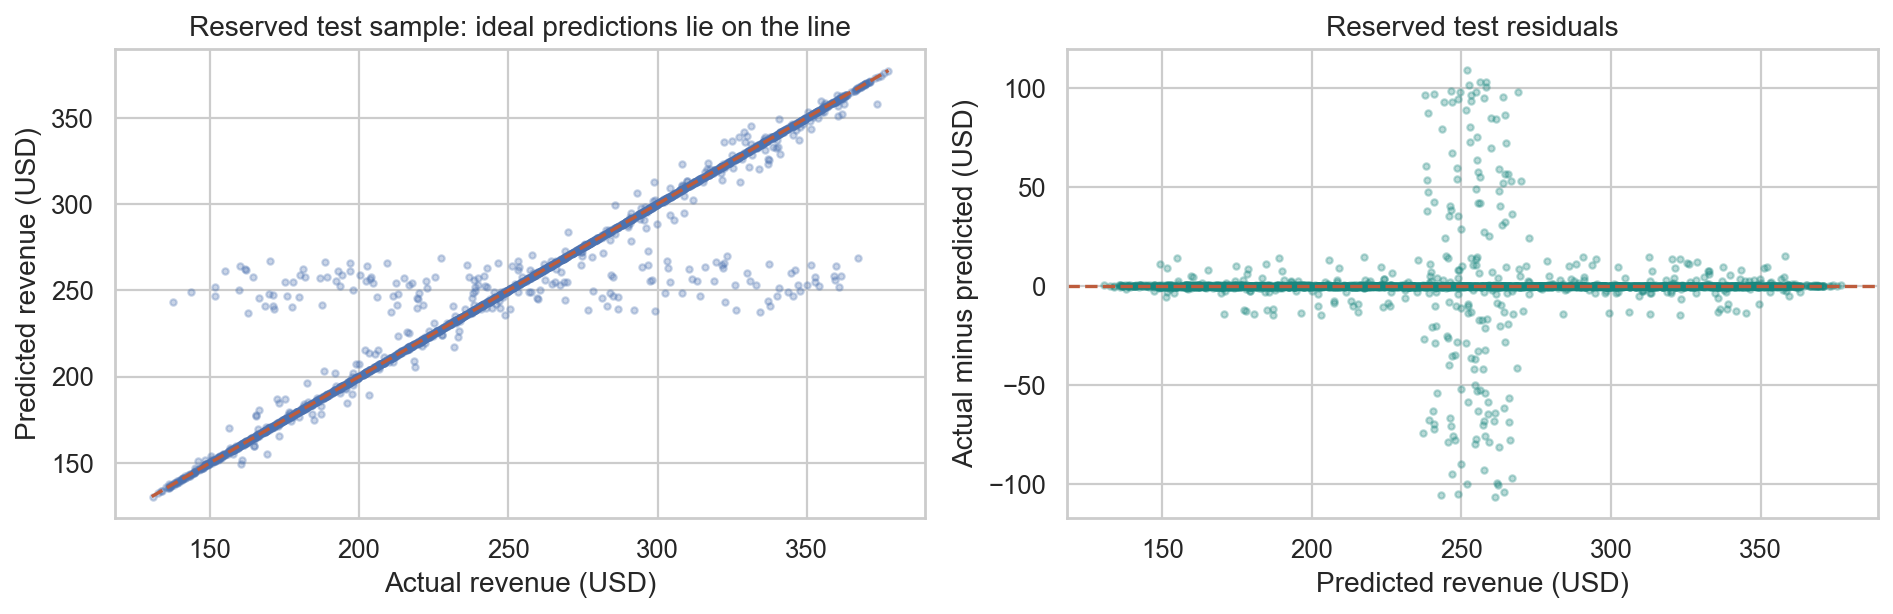

10_feature_importance


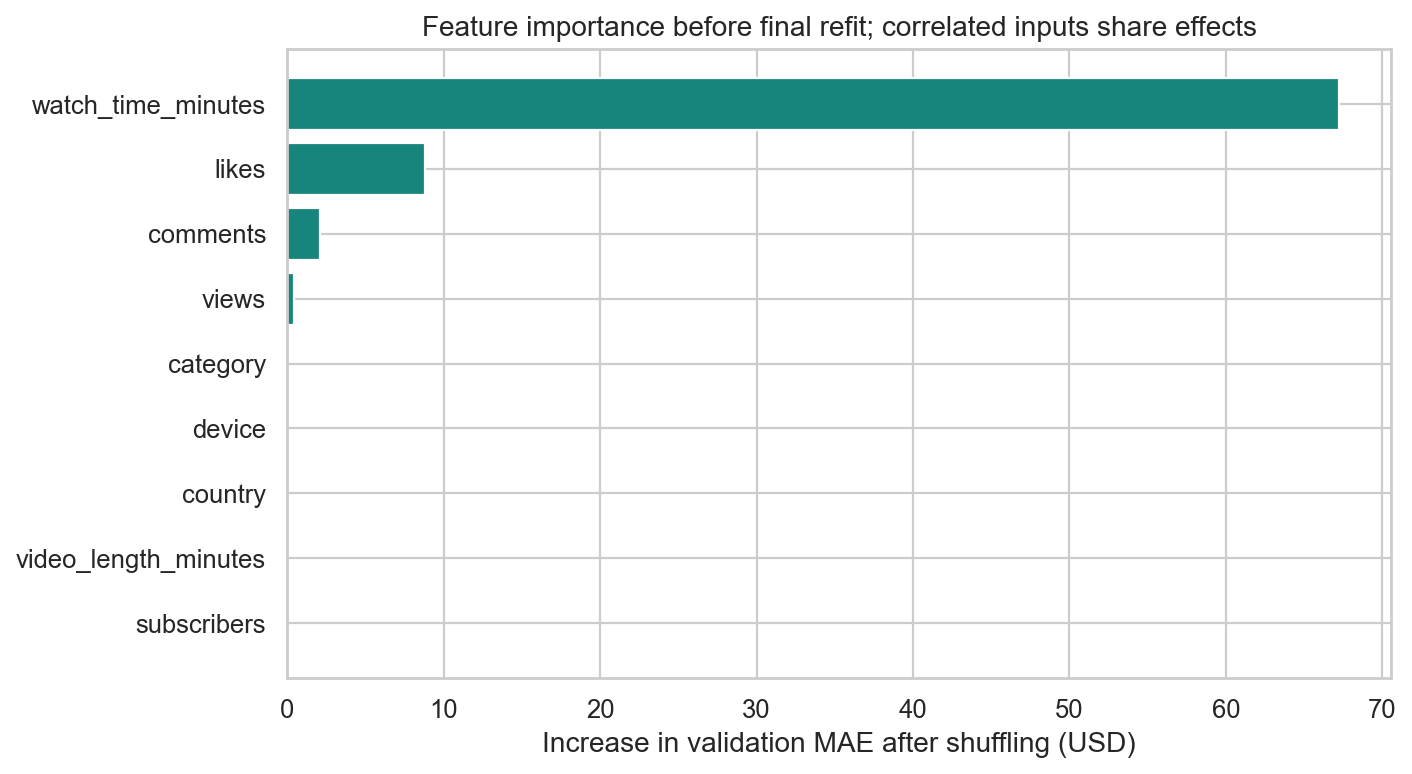

In [10]:
for path in sorted((project_root / "reports" / "figures").glob("*.png")):
    print(path.stem)
    display(Image(filename=str(path), width=850))

## 11. Feature importance without using test data for selection
Permutation importance shuffles one original input at a time and measures the change
in validation MAE. The feature function recomputes its ratios after shuffling. Importance
is measured before the final refit, using 1,500 validation rows and three repeats.
Correlated features share information; these values are not causal effects.

In [11]:
importance = pd.read_csv(project_root / "reports" / "feature_importance.csv")
display(importance.sort_values("mae_increase_usd", ascending=False).round(4))

,feature,mae_increase_usd,std_usd
3,watch_time_minutes,67.1988,0.4046
1,likes,8.8193,0.1434
2,comments,2.0777,0.0070
0,views,0.4249,0.0048
6,category,0.0059,0.0021
7,device,0.0050,0.0032
8,country,0.0011,0.0013
4,video_length_minutes,-0.0000,0.0004
5,subscribers,-0.0001,0.0001


## 12. Load the saved pipeline and predict
`joblib` uses Python serialization to store the fitted pipeline. Load only models you
created or trust. The Streamlit app checks the file hash and package versions before loading.
Named DataFrame columns keep feature ordering consistent.

In [12]:
pipeline = joblib.load(project_root / "models" / "revenue_pipeline.joblib")
metadata = read_json(project_root / "models" / "metadata.json")
inputs = metadata["defaults"].copy()
for column, choices in metadata["categories"].items():
    inputs[column] = choices[0]
revenue, notes = predict_revenue(pipeline, inputs, metadata)
print(f"Example estimate: ${revenue:.2f}")
print("Input notes:", notes)

Example estimate: $252.65
Input notes: []


## 13. Missing inputs and rejected extrapolation
Missing optional inputs use fitted medians. An input outside the supported numeric
ranges produces a helpful message. We do not silently clip predictions or imply
that the model has learned data ranges it has never seen.

In [13]:
unknown_watch = inputs.copy()
unknown_watch["watch_time_minutes"] = None
value, notes = predict_revenue(pipeline, unknown_watch, metadata)
print(f"Estimate with unknown watch time: ${value:.2f}")
print(notes)

unsupported = inputs.copy()
unsupported["views"] = 1000000
try:
    predict_revenue(pipeline, unsupported, metadata)
except ValueError as error:
    print("Expected validation message:", error)

Estimate with unknown watch time: $253.24
['watch time minutes is unknown; saved medians are used.']
Expected validation message: views is outside the fitted range (9,521.00 to 10,468.00). Use a value in this range.


## 14. Deliverables and how to present the project
The `data/cleaned_youtube_data.csv` export has imputed, unscaled values, missing flags
and the partition label. Its medians came from training + validation only. Always train
from the original CSV, not this descriptive export. The app's exploration page uses
deduplicated source observations with missingness intact.

Run `python -m streamlit run app.py` from the project folder. The four screens are
Overview, Explore Data, Predict Revenue and Model Results. Read the README and the
PDF guide for setup, code explanations and a 12-minute presentation outline.

**Conclusion:** watch time is the main observed predictor in this synthetic dataset.
Recording it accurately is more useful than claiming the model can recover missing
information. The narrow views range and inconsistent video identity limit generalization.
Real-world use would require representative, consistently defined revenue data and
evaluation on new channels and future periods.

**Sources:** [Project brief](https://docs.google.com/document/d/1zBCNNywwsDs3oEquJ7Q6Dwdt87_B5E-LVdzmjkOZOvw/edit)
and [provided dataset](https://drive.google.com/file/d/1joozv6lXGgvnYZxbdKlV4VpVp2rbR_7s/view).